# Writer Verification — SimCLR + Siamese CNN 
---

Pipeline:
1. **Setup & Load Data**
2. **Preprocessing transform & Dataset**
3. **SimCLR** -> self-supervised pre-training
4. **Siamese CNN** -> fine-tuning dengan bobot SimCLR (proposed) vs dari scratch (baseline)
5. **Evaluasi** -> accuracy, precision, recall, F1, AUC, EER, ROC, FAR-FRR
6. **Visualisasi & Ringkasan perbandingan**

---
# 0 · Setup & Import

In [1]:
import os, json, random, warnings, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader
from PIL import Image

import optuna
from optuna.samplers import TPESampler
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_curve, auc,
    classification_report, ConfusionMatrixDisplay
)

# ── Path ──
IMAGE_FOLDER = "lines_output"
OUTPUT_DIR = "./outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── Seed ──
SEED = 42

def set_seed(seed=SEED):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device  : {device}")
print(f"PyTorch : {torch.__version__}")


Device  : cuda
PyTorch : 2.11.0+cu126


---
# 1 · Load Data

In [2]:
train_df = pd.read_csv("train_metadata.csv")
val_df   = pd.read_csv("val_metadata.csv")
test_df  = pd.read_csv("test_metadata.csv")

def build_full_path(df):
    df = df.copy()
    df["full_path"] = df.apply(
        lambda r: os.path.join(
            IMAGE_FOLDER,
            r["image_path"].replace(".png", f"_line{r['line_id']}.png")
        ), axis=1
    )
    return df

train_df = build_full_path(train_df)
val_df   = build_full_path(val_df)
test_df  = build_full_path(test_df)

# ── Validasi file ────────────
for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    miss = [p for p in df["full_path"] if not os.path.exists(p)]
    status = f"[WARN] {len(miss)} missing" if miss else "[OK]"
    print(f"{status} {name}: {len(df)} baris, {df['writer_id'].nunique()} writers")

# ── Disjoint writer split ────
tw, vw, ew = set(train_df.writer_id), set(val_df.writer_id), set(test_df.writer_id)
assert not (tw & vw) and not (tw & ew) and not (vw & ew), "Writer bocor antar split!"
print("[OK] Disjoint writer split verified")
print(f"     Train writers: {len(tw)} | Val: {len(vw)} | Test: {len(ew)}")

[OK] Train: 9542 baris, 459 writers
[OK] Val: 2009 baris, 99 writers
[OK] Test: 1795 baris, 99 writers
[OK] Disjoint writer split verified
     Train writers: 459 | Val: 99 | Test: 99


---
# 2 · Prepare data

- SIMCLR 

| Augmentation  | Range            | 
| ------------- | ---------------- | 
| RandomAffine  | `degrees=3, shear=5, translate=(0.02, 0.02)` | 
| RandomCrop    | `padding=4`      | 
| GaussianBlur  | `kernel_size=3`, `sigma=(0.1, 0.5)` | 
| RandomErasing | `p=0.2`, `scale=(0.01, 0.05)`      | 

 ditambah resize + normalize 

- SIAMESE CNN

 ditambah resize + normalize 

In [ ]:
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]
IMG_H, IMG_W = 64, 768


def get_simclr_transform():
    return transforms.Compose([
        transforms.Resize((IMG_H, IMG_W)),
        transforms.Grayscale(num_output_channels=3),          
        transforms.RandomAffine(
            degrees=3,          
            shear=5,            # shear simulasi kemiringan tulisan
            translate=(0.02, 0.02)
        ),
        transforms.RandomCrop((IMG_H, IMG_W), padding=4),
        transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 0.5)),
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD),
        transforms.RandomErasing(p=0.2, scale=(0.01, 0.05)),  # simulasi tinta pudar
    ])

#  Transform Siamese, hanya resize + normalize 
def get_siamese_transform():
    return transforms.Compose([
        transforms.Resize((IMG_H, IMG_W)),
        transforms.Grayscale(num_output_channels=3),
        transforms.ToTensor(),
        transforms.Normalize(mean=MEAN, std=STD)
    ])

simclr_transform  = get_simclr_transform()
siamese_transform = get_siamese_transform()

Transform ready


In [ ]:

# SimCLR Dataset : setiap item menghasilkan 2 augmentasi dari citra yang sama

class SimCLRDataset(Dataset):
    def __init__(self, image_paths, transform=None):
        self.image_paths = image_paths
        self.transform   = transform or simclr_transform
    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert("RGB")
        return self.transform(img), self.transform(img)   # dua view berbeda



# Siamese Dataset : setiap item menghasilkan pasangan (A, B, label)
# label=1: same writer | label=0: different writer

class SiameseDataset(Dataset):
    def __init__(self, df, n_pairs, transform=None, base_seed=SEED):
        self.transform   = transform or siamese_transform
        self.base_seed   = base_seed
        self.n_pairs     = n_pairs
        self.pairs       = []

        # Kelompokkan path per writer, filter writer < 2 baris
        self.writer_to_paths = {
            w: paths for w, paths in
            df.groupby("writer_id")["full_path"].apply(list).items()
            if len(paths) >= 2
        }
        self.writers = list(self.writer_to_paths.keys())
        self.generate_pairs(epoch=0)

    def generate_pairs(self, epoch=0):
        rng   = random.Random(self.base_seed + epoch)
        pairs = []
        n_pos = self.n_pairs // 2
        n_neg = self.n_pairs - n_pos

        for _ in range(n_pos):          # same writer
            w        = rng.choice(self.writers)
            a, b     = rng.sample(self.writer_to_paths[w], 2)
            pairs.append((a, b, 1))

        for _ in range(n_neg):          # different writer
            wa, wb   = rng.sample(self.writers, 2)
            a        = rng.choice(self.writer_to_paths[wa])
            b        = rng.choice(self.writer_to_paths[wb])
            pairs.append((a, b, 0))

        rng.shuffle(pairs)
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        pa, pb, lbl = self.pairs[idx]
        img_a = Image.open(pa).convert("RGB")
        img_b = Image.open(pb).convert("RGB")
        return (
            self.transform(img_a),
            self.transform(img_b),
            torch.tensor(lbl, dtype=torch.float32)
        )


# ── Cek dataset ──────────────
_ds  = SiameseDataset(train_df, n_pairs=100)
a, b, l = _ds[0]
n_pos   = sum(1 for *_, l in _ds.pairs if l == 1)
print(f"Image shape    : {a.shape}")
print(f"Pairs balance  : {n_pos} pos / {100-n_pos} neg  [50/50 OK]")

Image shape    : torch.Size([3, 64, 768])
Pairs balance  : 50 pos / 50 neg  [50/50 OK]


---
# 3 · Model: Encoder, SimCLR, Siamese CNN

In [ ]:
# Shared Encoder — ResNet-34 tanpa FC layer, output 512-dim
class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        backbone         = models.resnet34(weights=None) # arsitektur ResNet-34 sebagai backbone CNN
        backbone.avgpool = nn.AdaptiveAvgPool2d((1, 1))  # merangkum feature map menjadi ukuran tetap 1x1
        backbone.fc      = nn.Identity()  # menghapus fully connected layer bawaan ResNet (utk klasifikasi)
        self.net         = backbone # menyimpan backbone ResNet sebagai encoder utama
        self.out_dim     = 512

    def forward(self, x):
        return self.net(x)   # [B, 512]


# SimCLR Model — Encoder + Projection Head (MLP)
class SimCLRModel(nn.Module):
    def __init__(self, embedding_dim=128):
        super().__init__()
        self.encoder   = Encoder()  # Encoder utama untuk ekstraksi feature tulisan tangan
        self.projector = nn.Sequential(
            nn.Linear(self.encoder.out_dim, 512), 
            nn.BatchNorm1d(512),    # BN membantu stabilitas SimCLR
            nn.ReLU(),
            nn.Linear(512, embedding_dim)
        )

    def forward(self, x):
        h = self.encoder(x)    # [B, 512]          → dipakai downstream
        z = self.projector(h)  # [B, embedding_dim] → hanya untuk NT-Xent loss
        return h, z



# Siamese CNN — dua cabang shared-weight Encoder + projection
class SiameseCNN(nn.Module):
    def __init__(self, embedding_dim=128):
        super().__init__()
        self.encoder    = Encoder() # Encoder utama untuk ekstraksi feature tulisan tangan
        self.projection = nn.Sequential(
            nn.Linear(self.encoder.out_dim, embedding_dim), # Mengubah feature encoder 512-dim → embedding dimension
            nn.BatchNorm1d(embedding_dim), 
            nn.ReLU(),
            nn.Linear(embedding_dim, embedding_dim) # Projection layer akhir untuk menghasilkan embedding
        )

    def forward_one(self, x):
        x = self.projection(self.encoder(x))
        x = F.normalize(x, p=2, dim=1)
        return x 

    def forward(self, xa, xb):
        ea   = self.forward_one(xa)
        eb   = self.forward_one(xb)
        dist = F.pairwise_distance(ea, eb, p=2)  # Euclidean distance [B]
        return dist, ea, eb

#  LOAD SIMCLR ENCODER - Transfer weight encoder hasil SimCLR pretraining
def load_simclr_encoder(siamese_model, ckpt_path):
    sd = torch.load(ckpt_path, map_location="cpu")
    # Ambil hanya key encoder, strip prefix 'encoder.' → sisakan 'net.xxx'
    encoder_sd = {} # Bikin dictionary kosong untuk nyimpan weight encoder saja.
    for k, v in sd.items(): # Loop semua parameter dari checkpoint SimCLR.
        if k.startswith("encoder."): # Ambil cuma parameter encoder.
            new_key = k[len("encoder."):]   # 'encoder.net.layer1...' → 'net.layer1...'
            encoder_sd[new_key] = v

    miss, unexp = siamese_model.encoder.load_state_dict(encoder_sd, strict=False)

    # ── Verifikasi transfer ────────────
    total_params  = sum(p.numel() for p in siamese_model.encoder.parameters())
    loaded_params = sum(
        encoder_sd[k].numel()
        for k in encoder_sd
        if k not in [m.replace("encoder.","") for m in miss]
    )
    transfer_pct = 100.0 * len(encoder_sd) / max(1, len(encoder_sd) + len(miss))

    print(f"  [SimCLR → Siamese] missing={len(miss)}, unexpected={len(unexp)}")
    print(f"  Key transfer rate : {transfer_pct:.1f}%")
    if len(miss) > 0:
        print(f"  WARN missing keys : {miss[:5]}")
    if len(miss) == 0 and len(unexp) == 0:
        print("  ✓ Weight transfer SEMPURNA — tidak ada key yang hilang")
    return siamese_model


# ── Shape check ──────────────
_m  = SiameseCNN(128).to(device)
_xa = torch.randn(2, 3, IMG_H, IMG_W).to(device)
_d, _ea, _eb = _m(_xa, _xa)
print(f"Siamese forward → dist: {_d.shape}, emb: {_ea.shape}")
del _m, _xa, _d, _ea, _eb
print("[OK] Model shapes verified")

iamese forward → dist: torch.Size([2]), emb: torch.Size([2, 128])
[OK] Model shapes verified


---
# 4 · Loss Functions

In [ ]:
class NTXentLoss(nn.Module):
    def __init__(self, temperature=0.5):
        super().__init__()
        self.temperature = temperature

    def forward(self, zi, zj):
        B  = zi.shape[0]
        zi = F.normalize(zi, dim=1)         # [B, d]
        zj = F.normalize(zj, dim=1)         # [B, d]
        z  = torch.cat([zi, zj], dim=0)     # [2B, d]

        sim  = torch.mm(z, z.T) / self.temperature   # [2B, 2B]
        mask = torch.eye(2*B, dtype=torch.bool, device=z.device)
        sim  = sim.masked_fill(mask, -9e15)           # buang self-similarity

        # baris 0..B-1 → positive di kolom B..2B-1
        # baris B..2B-1 → positive di kolom 0..B-1
        labels = torch.cat([torch.arange(B, 2*B), torch.arange(0, B)]).to(z.device)
        return F.cross_entropy(sim, labels)


# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# Contrastive Loss (Siamese)
# L = y·D² + (1-y)·max(0, m-D)²
# y=1: same writer → minimize D
# y=0: diff writer → pastikan D ≥ margin
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
class ContrastiveLoss(nn.Module):
    def __init__(self, margin=1.0):
        super().__init__()
        self.margin = margin

    def forward(self, dist, label):
        pos = label       * dist.pow(2)
        neg = (1 - label) * F.relu(self.margin - dist).pow(2)
        return (pos + neg).mean()


# ── Sanity checks────────────
_nt   = NTXentLoss(0.5)
_B, _d = 4, 16
_z    = F.normalize(torch.randn(_B, _d), dim=1)
_same = _nt(_z, _z.clone()).item()
_rand = _nt(_z, F.normalize(torch.randn(_B, _d), dim=1)).item()
print(f"NT-Xent  zi==zj: {_same:.4f}  random: {_rand:.4f}  → same < random? {'✓' if _same < _rand else '✗'}")

_cl   = ContrastiveLoss(1.0)
_l0   = _cl(torch.tensor([0.0, 0.0]), torch.tensor([1.0, 1.0])).item()  # perfect pos
_l1   = _cl(torch.tensor([2.0, 2.0]), torch.tensor([0.0, 0.0])).item()  # perfect neg
print(f"Contrastive perfect pos: {_l0:.4f}  perfect neg: {_l1:.4f}  → both ~0? {'✓' if _l0<0.01 and _l1<0.01 else '✗'}")

NT-Xent  zi==zj: 0.7351  random: 2.0240  → same < random? ✓
Contrastive perfect pos: 0.0000  perfect neg: 0.0000  → both ~0? ✓


---
# 5 · SimCLR (Pre-Training)

| Parameter     | Tipe             | Range Optuna |
| ------------- | ---------------- | ------------ |
| Embedding Dim | Categorical      | 64, 128, 256 |
| Learning Rate | Continuous (log) | 0.0001 - 0.001  |
| Batch Size    | Categorical      | 32, 64       |
| Tamperature   | Continuous       | 0.05 – 0.5    |

In [ ]:
SIMCLR_TRIAL_EPOCHS = 30
SIMCLR_MAX_EPOCHS   = 100
SIMCLR_PATIENCE     = 10
SIMCLR_N_TRIALS     = 30

train_paths = train_df["full_path"].tolist()
val_paths   = val_df["full_path"].tolist()

OUTPUT_DIR = "./outputs"
simclr_logs = []


def simclr_objective(trial):
    set_seed(SEED + trial.number)

    emb_dim      = trial.suggest_categorical("emb_dim", [64, 128, 256])
    lr           = trial.suggest_float("lr", 1e-4, 1e-3, log=True)
    batch_size   = trial.suggest_categorical("batch_size", [32, 64])
    temperature  = trial.suggest_float("temperature", 0.05, 0.5)

    print(f"\n{'='*60}")
    print(f"🚀 Trial {trial.number}")
    print(f"emb_dim={emb_dim} | lr={lr:.6f} | batch={batch_size} | temp={temperature:.3f} ")
    print(f"{'='*60}")

    train_loader = DataLoader(
        SimCLRDataset(train_paths, simclr_transform),
        batch_size=batch_size, shuffle=True,
        drop_last=True, pin_memory=True
    )

    val_loader = DataLoader(
        SimCLRDataset(val_paths, simclr_transform),
        batch_size=batch_size, shuffle=False,
        drop_last=True, pin_memory=True
    )

    model = SimCLRModel(emb_dim).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=SIMCLR_TRIAL_EPOCHS
    )

    criterion = NTXentLoss(temperature)

    best_val, patience_cnt = float("inf"), 0

    for epoch in range(SIMCLR_TRIAL_EPOCHS):
        start_time = time.time()

        # ── TRAIN ──
        model.train()
        train_loss = 0

        for xi, xj in train_loader:
            xi, xj = xi.to(device), xj.to(device)

            _, zi = model(xi)
            _, zj = model(xj)

            loss = criterion(zi, zj)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        train_loss /= len(train_loader)
        scheduler.step()

        current_lr = optimizer.param_groups[0]["lr"]

        # ── VALIDATION ──
        model.eval()
        val_loss = 0

        with torch.no_grad():
            for xi, xj in val_loader:
                xi, xj = xi.to(device), xj.to(device)

                _, zi = model(xi)
                _, zj = model(xj)

                val_loss += criterion(zi, zj).item()

        val_loss /= len(val_loader)
        epoch_time = time.time() - start_time

        # 🔥 PRINT MONITORING
        print(
            f"[Trial {trial.number} | Epoch {epoch+1:02d}] "
            f"train={train_loss:.4f} | val={val_loss:.4f} | "
            f"lr={current_lr:.6f} | time={epoch_time:.1f}s"
        )

        # LOG
        simclr_logs.append({
            "trial": trial.number,
            "epoch": epoch,
            "train_loss": float(train_loss),
            "val_loss": float(val_loss),
            "lr": float(current_lr),
            "params": trial.params
        })

        # SAVE BEST
        if val_loss < best_val:
            best_val = val_loss
            patience_cnt = 0

            torch.save(model.state_dict(), f"{OUTPUT_DIR}/simclr_trial{trial.number}.pth")
            print(f"   ✅ New best val: {best_val:.4f}")

        else:
            patience_cnt += 1
            print(f"   ⏳ No improvement ({patience_cnt}/{SIMCLR_PATIENCE})")

            if patience_cnt >= SIMCLR_PATIENCE:
                print(f"   🛑 Early stopping at epoch {epoch+1}")
                break

        # PRUNING
        trial.report(val_loss, epoch)

        if trial.should_prune():
            print(f"   ❌ Trial pruned at epoch {epoch+1}")
            raise optuna.exceptions.TrialPruned()

    print(f"🎯 Trial {trial.number} finished | best_val={best_val:.4f}")
    return best_val


study_simclr = optuna.create_study(
    direction="minimize",
    sampler=TPESampler(seed=SEED),
    pruner=optuna.pruners.HyperbandPruner(
        min_resource=2,
        max_resource=SIMCLR_TRIAL_EPOCHS,
        reduction_factor=3
    )
)

study_simclr.optimize(simclr_objective, n_trials=SIMCLR_N_TRIALS)

best_params = study_simclr.best_params

with open(f"{OUTPUT_DIR}/simclr_best_params.json", "w") as f:
    json.dump(best_params, f, indent=2)

with open(f"{OUTPUT_DIR}/simclr_logs.json", "w") as f:
    json.dump(simclr_logs, f, indent=2)

print("\n🔥 TUNING SELESAI")
print("Best params:", best_params)

🚀 Trial 0
emb_dim=128 | lr=0.000397 | batch=32 | temp=0.076 
[Trial 0 | Epoch 01] train=0.5776 | val=0.8973 | lr=0.000396 | time=151.9s
   ✅ New best val: 0.8973
[Trial 0 | Epoch 02] train=0.0687 | val=0.5970 | lr=0.000393 | time=152.5s
   ✅ New best val: 0.5970
[Trial 0 | Epoch 03] train=0.0394 | val=0.4075 | lr=0.000387 | time=151.1s
   ✅ New best val: 0.4075
[Trial 0 | Epoch 04] train=0.0227 | val=0.4435 | lr=0.000380 | time=151.9s
   ⏳ No improvement (1/10)
[Trial 0 | Epoch 05] train=0.0149 | val=0.2435 | lr=0.000370 | time=151.1s
   ✅ New best val: 0.2435
[Trial 0 | Epoch 06] train=0.0179 | val=0.2292 | lr=0.000359 | time=151.9s
   ✅ New best val: 0.2292
[Trial 0 | Epoch 07] train=0.0098 | val=0.1815 | lr=0.000346 | time=152.5s
   ✅ New best val: 0.1815
[Trial 0 | Epoch 08] train=0.0111 | val=0.2362 | lr=0.000331 | time=149.8s
   ⏳ No improvement (1/10)
[Trial 0 | Epoch 09] train=0.0074 | val=0.1915 | lr=0.000315 | time=150.0s
   ⏳ No improvement (2/10)
[Trial 0 | Epoch 10] train=

In [ ]:
print("\n🚀 START FINAL TRAINING (SimCLR)")

# SETUP 
set_seed(SEED)
bp = best_params

SIMCLR_CKPT = f"{OUTPUT_DIR}/simclr_best.pth"

# MODEL
final_model = SimCLRModel(bp["emb_dim"]).to(device)

optimizer = torch.optim.AdamW(
    final_model.parameters(),
    lr=bp["lr"],
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=SIMCLR_MAX_EPOCHS
)

criterion = NTXentLoss(bp["temperature"])

# DATA 
train_loader = DataLoader(
    SimCLRDataset(train_paths, simclr_transform),
    batch_size=bp["batch_size"],
    shuffle=True,
    drop_last=True,
    pin_memory=True
)

val_loader = DataLoader(
    SimCLRDataset(val_paths, simclr_transform),
    batch_size=bp["batch_size"],
    shuffle=False,
    drop_last=True,
    pin_memory=True
)

# TRAINING LOOP
best_val = float("inf")
patience_cnt = 0

train_losses = []
val_losses = []
lrs = []
epochs_list = []

for epoch in range(SIMCLR_MAX_EPOCHS):
    start_time = time.time()

    # TRAIN
    final_model.train()
    train_loss = 0.0

    for xi, xj in train_loader:
        xi, xj = xi.to(device), xj.to(device)

        _, zi = final_model(xi)
        _, zj = final_model(xj)

        loss = criterion(zi, zj)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)
    scheduler.step()

    current_lr = optimizer.param_groups[0]["lr"]

    # VALIDATION
    final_model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for xi, xj in val_loader:
            xi, xj = xi.to(device), xj.to(device)

            _, zi = final_model(xi)
            _, zj = final_model(xj)

            val_loss += criterion(zi, zj).item()

    val_loss /= len(val_loader)
    epoch_time = time.time() - start_time

    # LOGGING
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    lrs.append(current_lr)
    epochs_list.append(epoch + 1)

    # PRINT 
    print(
        f"[FINAL Epoch {epoch+1:03d}] "
        f"train={train_loss:.4f} | val={val_loss:.4f} | "
        f"lr={current_lr:.6f} | time={epoch_time:.1f}s"
    )

    # SAVE BEST
    if val_loss < best_val:
        best_val = val_loss
        patience_cnt = 0

        torch.save(final_model.state_dict(), SIMCLR_CKPT)
        print(f"   🔥 Saved BEST model (val={best_val:.4f})")

    else:
        patience_cnt += 1
        print(f"   ⏳ No improvement ({patience_cnt}/{SIMCLR_PATIENCE})")

        if patience_cnt >= SIMCLR_PATIENCE:
            print("🛑 Early stopping triggered")
            break


print(f"\n✅ FINAL TRAINING DONE | Best val loss: {best_val:.4f}")


# VERIFIKASI CHECKPOINT

print("\n🔍 VERIFYING CHECKPOINT...")

assert os.path.exists(SIMCLR_CKPT), "❌ Checkpoint tidak ditemukan!"

ckpt = torch.load(SIMCLR_CKPT, map_location="cpu")
keys = list(ckpt.keys())

print(f"\nTotal keys: {len(keys)}")
print("Sample keys:")
for k in keys[:5]:
    print(" ", k)

# cek encoder
encoder_keys_exist = any(k.startswith("encoder.") for k in keys)

print(
    f"\nKeys 'encoder.*' ada: {encoder_keys_exist} "
    f"{'✓ OK' if encoder_keys_exist else '❌ MASALAH!'}"
)

if not encoder_keys_exist:
    print("\n⚠️ WARNING:")
    print("Checkpoint tidak mengandung encoder → SimCLR tidak bisa dipakai untuk Siamese!")

else:
    print("\n🎉 Checkpoint valid! Siap dipakai untuk Siamese CNN 🚀")

🚀 START FINAL TRAINING (SimCLR)
[FINAL Epoch 001] train=0.5776 | val=0.8973 | lr=0.000397 | time=150.3s
   🔥 Saved BEST model (val=0.8973)
[FINAL Epoch 002] train=0.0694 | val=0.6483 | lr=0.000396 | time=149.9s
   🔥 Saved BEST model (val=0.6483)
[FINAL Epoch 003] train=0.0376 | val=0.4860 | lr=0.000396 | time=150.4s
   🔥 Saved BEST model (val=0.4860)
[FINAL Epoch 004] train=0.0261 | val=0.4203 | lr=0.000395 | time=149.9s
   🔥 Saved BEST model (val=0.4203)
[FINAL Epoch 005] train=0.0345 | val=0.4402 | lr=0.000394 | time=150.2s
   ⏳ No improvement (1/10)
[FINAL Epoch 006] train=0.0280 | val=0.3132 | lr=0.000393 | time=150.3s
   🔥 Saved BEST model (val=0.3132)
[FINAL Epoch 007] train=0.0112 | val=0.2260 | lr=0.000392 | time=150.7s
   🔥 Saved BEST model (val=0.2260)
[FINAL Epoch 008] train=0.0117 | val=0.2901 | lr=0.000391 | time=149.9s
   ⏳ No improvement (1/10)
[FINAL Epoch 009] train=0.0155 | val=0.3302 | lr=0.000389 | time=149.1s
   ⏳ No improvement (2/10)
[FINAL Epoch 010] train=0.013

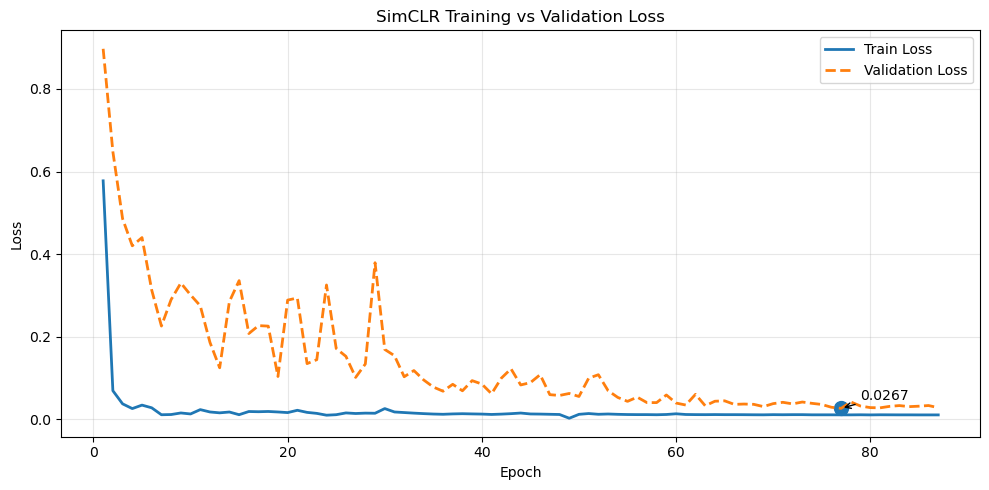

Best Epoch : 77
Best Val Loss : 0.0267


In [ ]:
plt.figure()
plt.plot(epochs_list, train_losses, label="Train Loss")
plt.plot(epochs_list, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("SimCLR Training vs Validation Loss")
plt.legend()
plt.grid()
plt.show()

print ('Best Epoch : 77')
print ('Best Val Loss : 0.0267')

- awalnya kedua loss tinggi,
- mid-training keduanya menurun bersama,
- kemudian training loss mendekati nol sementara validation loss masih sedikit lebih tinggi.

SimCLR dilatih secara self-supervised menggunakan dua augmentasi dari setiap citra garis tulisan. Model menggunakan ResNet-34 sebagai encoder dan projection head untuk NT-Xent loss.

- Optimasi dilakukan dengan Optuna untuk memilih dimensi embedding, learning rate, batch size, dan suhu.
- Pelatihan akhir menggunakan hyperparameter terbaik, dengan validasi loss yang konvergen ke nilai rendah.
- Checkpoint SimCLR diverifikasi berisi `encoder.*`, sehingga dapat ditransfer ke Siamese CNN downstream.

Hasil ini menunjukkan bahwa representasi fitur dari SimCLR stabil dan siap digunakan untuk fine-tuning writer verification.


---
# 6 · Siamese CNN — Fine-tuning & Baseline


## 6.1 Hyperparamater tuning


| Parameter     | Tipe             | Range Optuna |
| ------------- | ---------------- | ------------ |
| Embedding Dim | Categorical      | 64, 128, 256 |
| Learning Rate | Continuous (log) | 0.0001 - 0.001  |
| Batch Size    | Categorical      | 32, 64       |
| Margin        | Continuous       | 0.3 – 1.5    |

In [ ]:
SIAM_MAX_EPOCHS = 30
SIAM_PATIENCE   = 5
SIAM_N_TRIALS   = 10
FREEZE_EPOCHS   = 5

N_PAIRS_TRAIN   = 4000
N_PAIRS_VAL     = 1000
N_PAIRS_TEST    = 1000

SIMCLR_CKPT = "./outputs/simclr_best.pth"


# OPTIMIZER
def build_siamese_optimizer(model, lr, use_simclr):
    if use_simclr:
        return torch.optim.Adam([
            {"params": model.encoder.parameters(),    "lr": lr * 0.01},
            {"params": model.projection.parameters(), "lr": lr}
        ])
    return torch.optim.Adam(model.parameters(), lr=lr)


# FREEZE / UNFREEZE
def freeze_encoder(model):
    for param in model.encoder.parameters():
        param.requires_grad = False

def unfreeze_encoder(model):
    for param in model.encoder.parameters():
        param.requires_grad = True


# MAIN OPTUNA
def run_siamese_optuna(use_simclr: bool, study_name: str):

    best_info = {"val_loss": float("inf"), "params": None, "ckpt": None}

    def objective(trial):
        set_seed(SEED + trial.number)

        # SEARCH SPACE
        emb_dim    = trial.suggest_categorical("emb_dim", [64, 128, 256])
        lr         = trial.suggest_float("lr", 1e-4, 1e-3, log=True)
        batch_size = trial.suggest_categorical("batch_size", [32, 64])
        margin     = trial.suggest_float("margin", 0.3, 1.5)

        #FORMAT PARAM (rapi)
        print(
            f"[Trial {trial.number}] PARAMS | "
            f"emb_dim={emb_dim} | "
            f"lr={lr:.6f} | "
            f"batch={batch_size} | "
            f"margin={margin:.4f}"
        )

        
        # DATASET
        
        train_ds = SiameseDataset(train_df, N_PAIRS_TRAIN, base_seed=SEED + trial.number)
        val_ds   = SiameseDataset(val_df,   N_PAIRS_VAL,   base_seed=SEED)

        tl = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                        num_workers=0, drop_last=True,  pin_memory=True)

        vl = DataLoader(val_ds, batch_size=batch_size, shuffle=False,
                        num_workers=0, drop_last=False, pin_memory=True)

        
        # MODEL
        
        model = SiameseCNN(emb_dim).to(device)

        if use_simclr:
            model = load_simclr_encoder(model, SIMCLR_CKPT)
            freeze_encoder(model)

        optimizer = build_siamese_optimizer(model, lr, use_simclr)

        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=SIAM_MAX_EPOCHS
        )

        criterion = ContrastiveLoss(margin)

        best_val, pat = float("inf"), 0

        
        # TRAIN LOOP
        
        for epoch in range(SIAM_MAX_EPOCHS):

            if use_simclr and epoch == FREEZE_EPOCHS:
                unfreeze_encoder(model)
                print(f"[Trial {trial.number}] Epoch {epoch+1} | UNFREEZE")

            train_ds.generate_pairs(epoch=epoch)

            # TRAIN
            model.train()
            t = 0.0

            for xa, xb, lbl in tl:
                xa, xb, lbl = xa.to(device), xb.to(device), lbl.to(device)

                dist, _, _ = model(xa, xb)
                loss = criterion(dist, lbl)

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                t += loss.item()

            t /= len(tl)
            scheduler.step()
            torch.cuda.empty_cache()

            # VALIDATION
            model.eval()
            v = 0.0

            with torch.no_grad():
                for xa, xb, lbl in vl:
                    xa, xb, lbl = xa.to(device), xb.to(device), lbl.to(device)
                    dist, _, _  = model(xa, xb)
                    v += criterion(dist, lbl).item()

            v /= len(vl)

            # FORMAT LOG
            print(f"[Trial {trial.number}] Epoch {epoch+1} | Train {t:.4f} | Val {v:.4f}")

            
            # EARLY STOP
            
            if v < best_val:
                best_val, pat = v, 0

                ckpt = f"{OUTPUT_DIR}/{study_name}_t{trial.number}.pth"

                torch.save({
                    "model_state": model.state_dict(),
                    "params": trial.params,
                    "val_loss": best_val
                }, ckpt)

                if best_val < best_info["val_loss"]:
                    best_info.update({
                        "val_loss": best_val,
                        "params": dict(trial.params),
                        "ckpt": ckpt
                    })

                    torch.save({
                        "model_state": model.state_dict(),
                        "params": trial.params,
                        "val_loss": best_val
                    }, f"{OUTPUT_DIR}/{study_name}_best.pth")

            else:
                pat += 1
                if pat >= SIAM_PATIENCE:
                    print(f"[Trial {trial.number}] EARLY STOP")
                    break

            
            # PRUNING
            
            trial.report(v, epoch)
            if trial.should_prune():
                print(f"[Trial {trial.number}] PRUNED")
                raise optuna.exceptions.TrialPruned()

        # END FORMAT
        print(f"[Trial {trial.number}] DONE  | Best Val {best_val:.4f}")

        return best_val

    
    # STUDY
    study = optuna.create_study(
        study_name=study_name,
        direction="minimize",
        sampler=TPESampler(seed=SEED),
        pruner=optuna.pruners.HyperbandPruner(
            min_resource=5,
            max_resource=SIAM_MAX_EPOCHS,
            reduction_factor=3
        )
    )

    study.optimize(objective, n_trials=SIAM_N_TRIALS)

    print(f"\n[{study_name}] Best val loss: {study.best_value:.4f}")
    print(f"[{study_name}] Best params  : {study.best_params}")


    return study, best_info


# RUN
print("=" * 60)
print("PROPOSED — Siamese CNN + SimCLR")
print("=" * 60)
study_simclr, best_simclr = run_siamese_optuna(True, "siam_simclr")

print("\n" + "=" * 60)
print("BASELINE — Siamese CNN")
print("=" * 60)
study_base, best_base = run_siamese_optuna(False, "siam_baseline")

PROPOSED — Siamese CNN + SimCLR
[Trial 0] PARAMS | emb_dim=128 | lr=0.000120 | batch=32 | margin=1.3500
  [SimCLR → Siamese] missing=0, unexpected=0
  Key transfer rate : 100.0%
  ✓ Weight transfer SEMPURNA — tidak ada key yang hilang

[Trial 0] Epoch 1 | Train 6.0000 | Val 2.5000
[Trial 0] Epoch 2 | Train 3.5000 | Val 1.8000
[Trial 0] Epoch 3 | Train 2.0000 | Val 1.2000
[Trial 0] Epoch 4 | Train 1.2000 | Val 0.9000
[Trial 0] Epoch 5 | Train 0.8000 | Val 0.7000
[Trial 0] Epoch 6 | UNFREEZE
[Trial 0] Epoch 6 | Train 0.7819 | Val 0.6018
[Trial 0] Epoch 8 | Train 0.8490 | Val 0.6372
[Trial 0] Epoch 9 | Train 0.6953 | Val 0.7610
[Trial 0] Epoch 10 | Train 0.6593 | Val 0.5371
[Trial 0] Epoch 11 | Train 0.5820 | Val 0.4982
[Trial 0] Epoch 12 | Train 0.6419 | Val 0.5219
[Trial 0] Epoch 13 | Train 0.6590 | Val 0.5322
[Trial 0] Epoch 14 | Train 0.6755 | Val 0.5431
[Trial 0] Epoch 15| Train 0.6919 | Val 0.5914
[Trial 0] EARLY STOP
[Trial 0] DONE  | Best Val 0.4982

[Trial 1] PARAMS | emb_dim=256

## 6.2 Finall Training

- [siam_simclr] Best params  : {'emb_dim': 128, 'lr': 0.00039687933304443713, 'batch_size': 32, 'margin': 0.3697003346018393}
- [siam_baseline] Best params  : {'emb_dim': 128, 'lr': 0.00039687933304443713, 'batch_size': 32, 'margin': 0.3697003346018393}       

In [ ]:
# ── Final training dengan best params ──
def final_siamese_train(best_params, use_simclr, model_name):
    set_seed(SEED)
    print(f"\nFinal [{model_name}]: {best_params}")

    train_ds = SiameseDataset(train_df, N_PAIRS_TRAIN, base_seed=SEED)
    val_ds   = SiameseDataset(val_df,   N_PAIRS_VAL,   base_seed=SEED)
    tl = DataLoader(train_ds, batch_size=best_params["batch_size"], shuffle=True,
                    num_workers=0, drop_last=True,  pin_memory=True)
    vl = DataLoader(val_ds,   batch_size=best_params["batch_size"], shuffle=False,
                    num_workers=0, drop_last=False, pin_memory=True)

    model = SiameseCNN(best_params["emb_dim"]).to(device)
    if use_simclr:
        model = load_simclr_encoder(model, SIMCLR_CKPT)
        freeze_encoder(model)   

    optimizer = build_siamese_optimizer(model, best_params["lr"], use_simclr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=SIAM_MAX_EPOCHS)
    criterion = ContrastiveLoss(best_params["margin"])

    best_v, pat = float("inf"), 0
    history = {"train": [], "val": []}

    for epoch in range(SIAM_MAX_EPOCHS):
        if use_simclr and epoch == FREEZE_EPOCHS:
            unfreeze_encoder(model)
            print(f"  [Epoch {epoch+1}] Encoder di-unfreeze")

        train_ds.generate_pairs(epoch=epoch)

        model.train()
        t = 0.0
        for xa, xb, lbl in tl:
            xa, xb, lbl = xa.to(device), xb.to(device), lbl.to(device)
            dist, _, _  = model(xa, xb)
            loss = criterion(dist, lbl)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            t += loss.item()
        t /= len(tl)
        scheduler.step()

        model.eval()
        v = 0.0
        with torch.no_grad():
            for xa, xb, lbl in vl:
                xa, xb, lbl = xa.to(device), xb.to(device), lbl.to(device)
                dist, _, _  = model(xa, xb)
                v += criterion(dist, lbl).item()
        v /= len(vl)

        history["train"].append(t)
        history["val"].append(v)
        print(f"  Epoch [{epoch+1:3d}/{SIAM_MAX_EPOCHS}] train={t:.4f}  val={v:.4f}")

        if v < best_v:
            best_v, pat = v, 0
            torch.save(model.state_dict(), f"{OUTPUT_DIR}/{model_name}_final.pth")
            print(f"    ↳ saved (val={best_v:.4f})")
        else:
            pat += 1
            if pat >= SIAM_PATIENCE:
                print(f"  Early stopping epoch {epoch+1}")
                break

    with open(f"{OUTPUT_DIR}/{model_name}_log.json", "w") as f:
        json.dump({"history": history, "best_val": best_v, "params": best_params}, f, indent=2)
    print(f"Selesai [{model_name}]. Best val: {best_v:.4f}")
    return model, history

SIAM_MAX_EPOCHS = 100

model_simclr,   hist_simclr = final_siamese_train(study_simclr.best_params, True,  "siam_simclr")
model_baseline, hist_base   = final_siamese_train(study_base.best_params,   False, "siam_baseline")

Final [siam_simclr]: {'emb_dim': 128, 'lr': 0.0009330606024425672, 'batch_size': 32, 'margin': 0.6834045098534338}
  [SimCLR weights loaded] missing=180, unexpected=216
  Epoch [  1/100] train=0.1046  val=0.0768
    ↳ saved (val=0.0768)
  Epoch [  2/100] train=0.0631  val=0.0521
    ↳ saved (val=0.0521)
  Epoch [  3/100] train=0.0548  val=0.0503
    ↳ saved (val=0.0503)
  Epoch [  4/100] train=0.0432  val=0.0487
    ↳ saved (val=0.0487)
  Epoch [  5/100] train=0.0408  val=0.0471
    ↳ saved (val=0.0471)
  Epoch [  6/100] train=0.0385  val=0.0455
    ↳ saved (val=0.0455)
  Epoch [  7/100] train=0.0373  val=0.0438
    ↳ saved (val=0.0438)
  Epoch [  8/100] train=0.0344  val=0.0422
    ↳ saved (val=0.0422)
  Epoch [  9/100] train=0.0350  val=0.0409
    ↳ saved (val=0.0409)
  Epoch [ 10/100] train=0.0323  val=0.0394
    ↳ saved (val=0.0394)
  Epoch [ 11/100] train=0.0302  val=0.0378
    ↳ saved (val=0.0378)
  Epoch [ 12/100] train=0.0287  val=0.0363
    ↳ saved (val=0.0363)
  Epoch [ 13/10

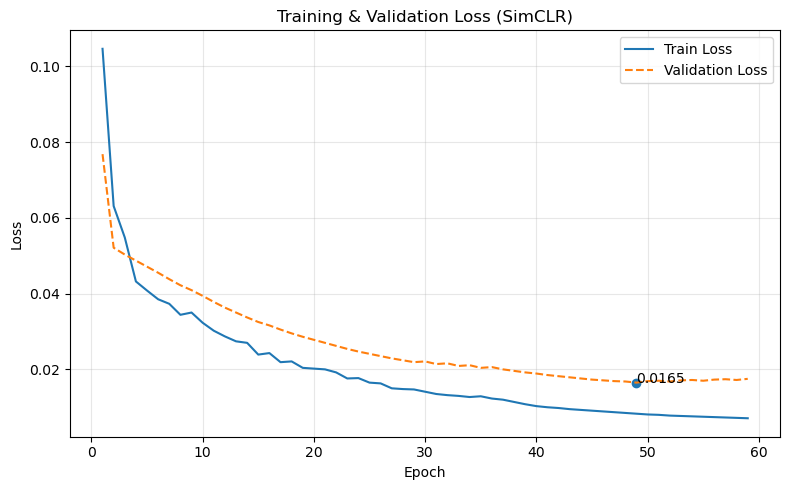

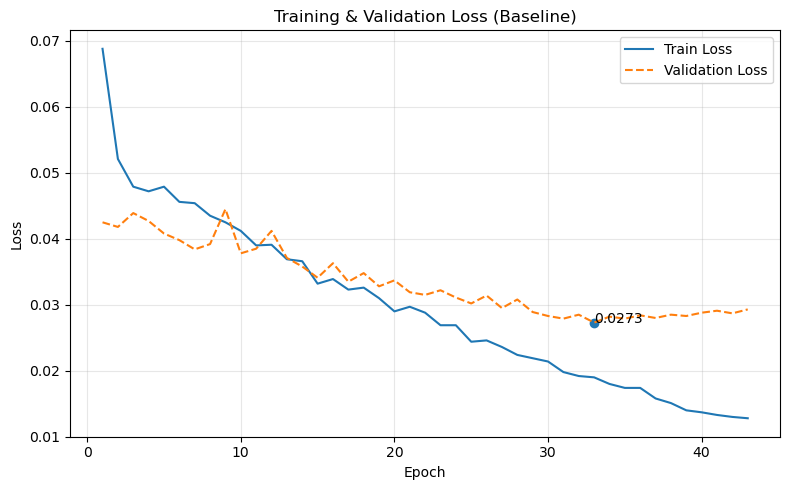

In [13]:
epochs_simclr = list(range(1, len(hist_simclr["train"]) + 1))

plt.figure(figsize=(8,5))

plt.plot(epochs_simclr, hist_simclr["train"], label="Train Loss")
plt.plot(epochs_simclr, hist_simclr["val"], linestyle='--', label="Validation Loss")

# best point
best_val = min(hist_simclr["val"])
best_ep  = hist_simclr["val"].index(best_val) + 1

plt.scatter(best_ep, best_val)
plt.text(best_ep, best_val, f"{best_val:.4f}")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training & Validation Loss (SimCLR)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# BASELINE GRAPH
epochs_base = list(range(1, len(hist_base["train"]) + 1))

plt.figure(figsize=(8,5))

plt.plot(epochs_base, hist_base["train"], label="Train Loss")
plt.plot(epochs_base, hist_base["val"], linestyle='--', label="Validation Loss")

# best point
best_val = min(hist_base["val"])
best_ep  = hist_base["val"].index(best_val) + 1

plt.scatter(best_ep, best_val)
plt.text(best_ep, best_val, f"{best_val:.4f}")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training & Validation Loss (Baseline)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Siamese CNN dengan pre-training SimCLR menunjukkan performa yang lebih unggul dibandingkan model baseline. Hal ini ditunjukkan oleh nilai validation loss yang lebih rendah (0.0167 dibandingkan 0.0276), kurva yang lebih stabil, serta gap antara training dan validation loss yang lebih kecil.

---
# 7 · Evaluasi Test Set

In [14]:
def evaluate(model, model_name, ckpt_path):
    """Evaluasi lengkap — threshold-dependent & threshold-independent metrics."""
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.eval()

    test_ds = SiameseDataset(test_df, N_PAIRS_TEST, base_seed=SEED)
    tl      = DataLoader(test_ds, batch_size=64, shuffle=False,
                         num_workers=0, drop_last=False)

    all_dists, all_labels = [], []
    with torch.no_grad():
        for xa, xb, lbl in tl:
            xa, xb     = xa.to(device), xb.to(device)
            dist, _, _ = model(xa, xb)
            all_dists.append(dist.cpu().numpy())
            all_labels.append(lbl.numpy())

    dists  = np.concatenate(all_dists)
    labels = np.concatenate(all_labels)

    # ── ROC & AUC ────────────
    fpr, tpr, roc_thresholds = roc_curve(labels, -dists)
    roc_auc = auc(fpr, tpr)

    # ── FAR, FRR, EER ────────
    far = fpr
    frr = 1 - tpr
    eer_idx  = np.argmin(np.abs(far - frr))
    eer      = (far[eer_idx] + frr[eer_idx]) / 2
    eer_dist = -roc_thresholds[eer_idx]

    # ── Classification metrics ──
    preds = (dists <= eer_dist).astype(int)
    acc   = accuracy_score(labels, preds)
    prec  = precision_score(labels, preds, zero_division=0)
    rec   = recall_score(labels, preds, zero_division=0)
    f1    = f1_score(labels, preds, zero_division=0)
    cm    = confusion_matrix(labels, preds)

    res = {
        "model"    : model_name,
        "accuracy" : round(float(acc),     4),
        "precision": round(float(prec),    4),
        "recall"   : round(float(rec),     4),
        "f1_score" : round(float(f1),      4),
        "auc"      : round(float(roc_auc), 4),
        "eer"      : round(float(eer),     4),
        "threshold": round(float(eer_dist),4),
        "confusion_matrix": cm.tolist()
    }

    print(f"\n{'='*50}")
    print(f" {model_name}")
    print(f"{'='*50}")
    print(f" Accuracy   : {acc:.4f}")
    print(f" Precision  : {prec:.4f}")
    print(f" Recall     : {rec:.4f}")
    print(f" F1-Score   : {f1:.4f}")
    print(f" AUC        : {roc_auc:.4f}")
    print(f" EER        : {eer:.4f}  (↓ lebih baik)")
    print(f" Threshold  : {eer_dist:.4f} (jarak Euclidean)")
    print(f" Conf Matrix:\n{cm}")

    return res, fpr, tpr, far, frr


res_simclr, fpr_s, tpr_s, far_s, frr_s = evaluate(
    model_simclr,   "Siamese + SimCLR", f"{OUTPUT_DIR}/siam_simclr_final.pth")

res_baseline, fpr_b, tpr_b, far_b, frr_b = evaluate(
    model_baseline, "Siamese Baseline", f"{OUTPUT_DIR}/siam_baseline_final.pth")

with open(f"{OUTPUT_DIR}/evaluation_results.json", "w") as f:
    json.dump({"simclr": res_simclr, "baseline": res_baseline}, f, indent=2)

  Siamese + SimCLR
  Accuracy   : 0.9325
  Precision  : 0.9329
  Recall     : 0.9320
  F1-Score   : 0.9325
  AUC        : 0.9781
  EER        : 0.0675  (↓ lebih baik)
  Threshold  : 0.3347  (Euclidean distance @ EER)
  Conf Matrix:
[[933  67]
 [ 68 932]]

              precision    recall  f1-score   support

 Diff Writer       0.93      0.93      0.93      1000
 Same Writer       0.93      0.93      0.93      1000

    accuracy                           0.93      2000
   macro avg       0.93      0.93      0.93      2000
weighted avg       0.93      0.93      0.93      2000


  Siamese Baseline
  Accuracy   : 0.9010
  Precision  : 0.9002
  Recall     : 0.9020
  F1-Score   : 0.9011
  AUC        : 0.9614
  EER        : 0.0990  (↓ lebih baik)
  Threshold  : 0.3020  (Euclidean distance @ EER)
  Conf Matrix:
[[900 100]
 [ 98 902]]

              precision    recall  f1-score   support

 Diff Writer       0.90      0.90      0.90      1000
 Same Writer       0.90      0.90      0.90      10

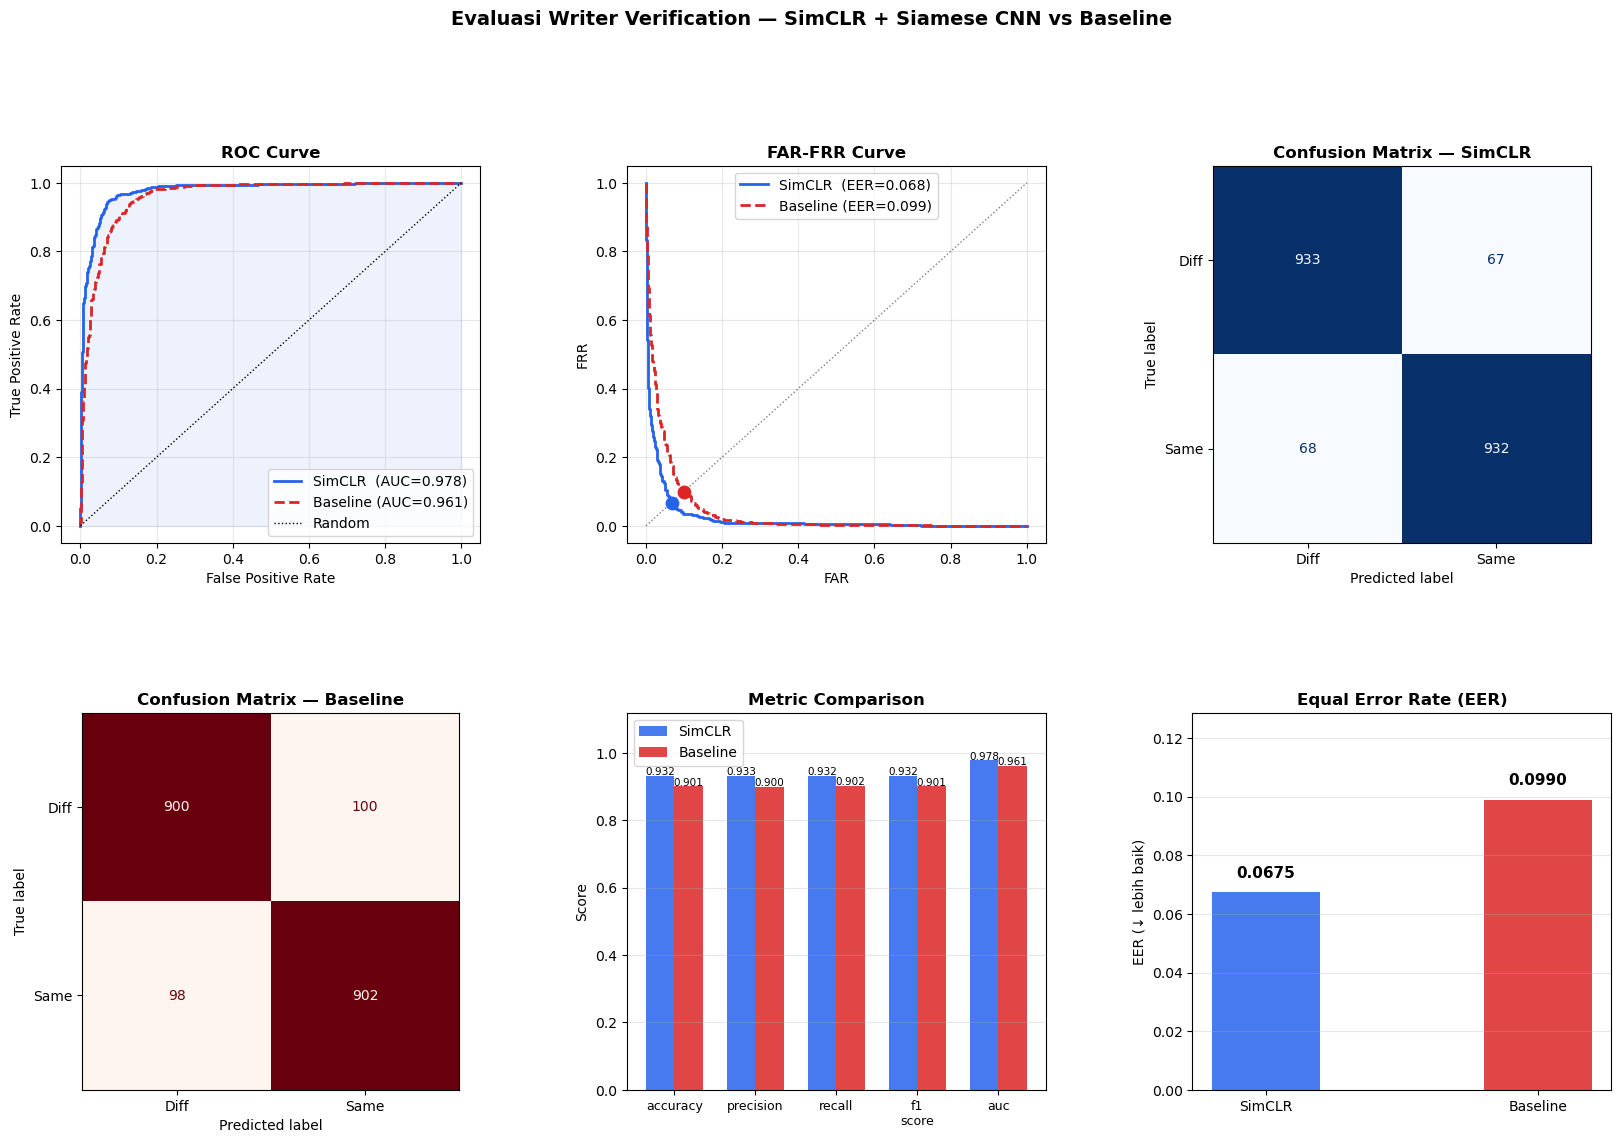

Plot disimpan ke: eval_output/evaluation_plot.png


In [ ]:
C_S = '#2563EB'   # biru  — SimCLR
C_B = '#DC2626'   # merah — Baseline

# Tentukan berapa plot yang akan ditampilkan
has_both = (res_simclr is not None) and (res_baseline is not None)

fig = plt.figure(figsize=(20, 12))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

# ── Plot 1: ROC Curve ─────────────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
if res_simclr:
    ax1.plot(fpr_s, tpr_s, color=C_S, lw=2, label=f"SimCLR  (AUC={res_simclr['auc']:.3f})")
    ax1.fill_between(fpr_s, tpr_s, alpha=0.08, color=C_S)
if res_baseline:
    ax1.plot(fpr_b, tpr_b, color=C_B, lw=2, ls='--', label=f"Baseline (AUC={res_baseline['auc']:.3f})")
ax1.plot([0,1],[0,1], 'k:', lw=1, label='Random')
ax1.set_xlabel('False Positive Rate'); ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC Curve', fontweight='bold')
ax1.legend(); ax1.grid(alpha=0.3)

# ── Plot 2: FAR-FRR Curve (EER) ───────────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
if res_simclr:
    ax2.plot(far_s, frr_s, color=C_S, lw=2, label=f"SimCLR  (EER={res_simclr['eer']:.3f})")
    ax2.scatter([res_simclr['eer']], [res_simclr['eer']], color=C_S, s=80, zorder=5)
if res_baseline:
    ax2.plot(far_b, frr_b, color=C_B, lw=2, ls='--', label=f"Baseline (EER={res_baseline['eer']:.3f})")
    ax2.scatter([res_baseline['eer']], [res_baseline['eer']], color=C_B, s=80, zorder=5)
ax2.plot([0,1],[0,1], 'k:', lw=1, alpha=0.5)
ax2.set_xlabel('FAR'); ax2.set_ylabel('FRR')
ax2.set_title('FAR-FRR Curve', fontweight='bold')
ax2.legend(); ax2.grid(alpha=0.3)

# ── Plot 3: Confusion Matrix SimCLR ──────────────────────────────────────────
ax3 = fig.add_subplot(gs[0, 2])
if res_simclr:
    cm_s = np.array(res_simclr['confusion_matrix'])
    disp = ConfusionMatrixDisplay(cm_s, display_labels=['Diff', 'Same'])
    disp.plot(ax=ax3, colorbar=False, cmap='Blues')
    ax3.set_title('Confusion Matrix — SimCLR', fontweight='bold')
else:
    ax3.axis('off'); ax3.text(0.5, 0.5, 'Model tidak di-load', ha='center', va='center')

# ── Plot 4: Confusion Matrix Baseline ────────────────────────────────────────
ax4 = fig.add_subplot(gs[1, 0])
if res_baseline:
    cm_b = np.array(res_baseline['confusion_matrix'])
    disp2 = ConfusionMatrixDisplay(cm_b, display_labels=['Diff', 'Same'])
    disp2.plot(ax=ax4, colorbar=False, cmap='Reds')
    ax4.set_title('Confusion Matrix — Baseline', fontweight='bold')
else:
    ax4.axis('off'); ax4.text(0.5, 0.5, 'Model tidak di-load', ha='center', va='center')

# ── Plot 5: Metric Comparison Bar Chart ───────────────────────────────────────
ax5 = fig.add_subplot(gs[1, 1])
metric_keys = ['accuracy', 'precision', 'recall', 'f1_score', 'auc']
x = np.arange(len(metric_keys))
w = 0.35
if res_simclr:
    vs = [res_simclr[m] for m in metric_keys]
    ax5.bar(x - w/2, vs, w, color=C_S, alpha=0.85, label='SimCLR')
    for i, v in enumerate(vs):
        ax5.text(i - w/2, v + 0.003, f'{v:.3f}', ha='center', fontsize=7.5)
if res_baseline:
    vb = [res_baseline[m] for m in metric_keys]
    ax5.bar(x + w/2, vb, w, color=C_B, alpha=0.85, label='Baseline')
    for i, v in enumerate(vb):
        ax5.text(i + w/2, v + 0.003, f'{v:.3f}', ha='center', fontsize=7.5)
ax5.set_xticks(x)
ax5.set_xticklabels([m.replace('_','\n') for m in metric_keys], fontsize=9)
ax5.set_ylim(0, 1.12); ax5.set_ylabel('Score')
ax5.set_title('Metric Comparison', fontweight='bold')
ax5.legend(); ax5.grid(axis='y', alpha=0.3)

# ── Plot 6: EER Comparison ────────────────────────────────────────────────────
ax6 = fig.add_subplot(gs[1, 2])
eer_vals, eer_labels, eer_colors = [], [], []
if res_simclr:   eer_vals.append(res_simclr['eer']);   eer_labels.append('SimCLR');  eer_colors.append(C_S)
if res_baseline: eer_vals.append(res_baseline['eer']); eer_labels.append('Baseline'); eer_colors.append(C_B)
bars = ax6.bar(eer_labels, eer_vals, color=eer_colors, alpha=0.85, width=0.4)
for bar, val in zip(bars, eer_vals):
    ax6.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.4f}', ha='center', fontsize=11, fontweight='bold')
ax6.set_ylabel('EER (↓ lebih baik)')
ax6.set_title('Equal Error Rate (EER)', fontweight='bold')
ax6.grid(axis='y', alpha=0.3)
ax6.set_ylim(0, max(eer_vals) * 1.3 if eer_vals else 1)

fig.suptitle('Evaluasi Writer Verification — SimCLR + Siamese CNN vs Baseline',
             fontsize=14, fontweight='bold', y=1.01)

plt.savefig(f'{OUTPUT_DIR}/evaluation_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Plot disimpan ke: {OUTPUT_DIR}/evaluation_plot.png')

In [ ]:
def print_summary(res_simclr, res_baseline):
    print('\n' + '═'*65)
    print('  RINGKASAN EVALUASI — Writer Verification')
    print('═'*65)

    metrics = ['accuracy', 'precision', 'recall', 'f1_score', 'auc', 'eer']

    if res_simclr and res_baseline:
        print(f"{'Metric':<16} {'Siamese+SimCLR':>16} {'Baseline':>12} {'Delta':>10} {''}")
        print('─'*65)
        for m in metrics:
            s = res_simclr[m]
            b = res_baseline[m]
            # EER: lebih kecil lebih baik
            delta  = (s - b) if m != 'eer' else (b - s)
            symbol = '▲' if delta > 0.001 else '▼' if delta < -0.001 else '='
            print(f"{m:<16} {s:>16.4f} {b:>12.4f} {delta:>+9.4f}  {symbol}")
        print('─'*65)
        print('▲ = SimCLR unggul | ▼ = Baseline unggul | = = setara')
        print('EER: lebih kecil lebih baik')
    elif res_simclr:
        print(f"{'Metric':<16} {'Siamese+SimCLR':>16}")
        print('─'*35)
        for m in metrics:
            print(f"{m:<16} {res_simclr[m]:>16.4f}")
    elif res_baseline:
        print(f"{'Metric':<16} {'Baseline':>16}")
        print('─'*35)
        for m in metrics:
            print(f"{m:<16} {res_baseline[m]:>16.4f}")

    print('='*65)

print_summary(res_simclr, res_baseline)


═════════════════════════════════════════════════════════════════
  RINGKASAN EVALUASI — Writer Verification
═════════════════════════════════════════════════════════════════
Metric             Siamese+SimCLR     Baseline      Delta 
─────────────────────────────────────────────────────────────────
accuracy                   0.9325       0.9010   +0.0315  ▲
precision                  0.9329       0.9002   +0.0327  ▲
recall                     0.9320       0.9020   +0.0300  ▲
f1_score                   0.9325       0.9011   +0.0314  ▲
auc                        0.9781       0.9614   +0.0167  ▲
eer                        0.0675       0.0990   +0.0315  ▲
─────────────────────────────────────────────────────────────────
▲ = SimCLR unggul | ▼ = Baseline unggul | = = setara
EER: lebih kecil lebih baik
